# 05 · Hyperparameter tuning
Small grids for each model family, scored on **validation AUC only**. The test set is not used here, so the
final evaluation in 04 stays a single, unbiased look at test data.

| Model | Grid | Configs |
| --- | --- | --- |
| Logistic regression | C ∈ {0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1} | 7 |
| PCA + random forest | components ∈ {20, 50, 100} × trees ∈ {100, 300} × max depth ∈ {10, unlimited} | 12 |
| CNN | learning rate ∈ {1e-3, 3e-4} × dropout ∈ {0.3, 0.5}, 15 epochs, early stopping (patience 4) | 4 |

The CNN grid uses 15 epochs (instead of 30) so all four runs fit in about 7 minutes. Each run stays well
under the 5-minute per-model budget.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import itertools
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline

from config import DATA_DIR, FIG_DIR, RESULTS_DIR, SEED, set_seeds

set_seeds()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
d = np.load(DATA_DIR / "processed.npz")
Xtr, ytr, Xva, yva = d["flat_train"], d["y_train"], d["flat_val"], d["y_val"]
Itr, Iva = d["img_train"], d["img_val"]
class_weights = {int(k): v for k, v in json.loads((DATA_DIR / "class_weights.json").read_text()).items()}
nb_start = time.perf_counter()

## Logistic regression: regularisation strength C

In [2]:
lr_rows = []
for C in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]:
    t0 = time.perf_counter()
    m = LogisticRegression(C=C, class_weight="balanced", max_iter=3000, random_state=SEED).fit(Xtr, ytr)
    lr_rows.append({"C": C, "val_auc": roc_auc_score(yva, m.predict_proba(Xva)[:, 1]),
                    "train_auc": roc_auc_score(ytr, m.predict_proba(Xtr)[:, 1]),
                    "seconds": time.perf_counter() - t0})
lr_res = pd.DataFrame(lr_rows)
lr_res.to_csv(RESULTS_DIR / "tuning_logreg.csv", index=False)
lr_res.round(4)

,C,val_auc,train_auc,seconds
0,0.001,0.9886,0.9893,0.0542
1,0.003,0.9908,0.9917,0.0273
2,0.010,0.9916,0.9939,0.0307
3,0.030,0.9914,0.9959,0.0369
4,0.100,0.9906,0.9979,0.0491
5,0.300,0.9889,0.9991,0.0656
6,1.000,0.9865,0.9998,0.0865


## PCA + random forest

In [3]:
rf_rows = []
for k, n_trees, depth in itertools.product([20, 50, 100], [100, 300], [10, None]):
    t0 = time.perf_counter()
    m = make_pipeline(
        PCA(n_components=k, random_state=SEED),
        RandomForestClassifier(n_estimators=n_trees, max_depth=depth, class_weight="balanced",
                               n_jobs=-1, random_state=SEED),
    ).fit(Xtr, ytr)
    rf_rows.append({"components": k, "trees": n_trees, "max_depth": "unlimited" if depth is None else depth,
                    "val_auc": roc_auc_score(yva, m.predict_proba(Xva)[:, 1]),
                    "seconds": time.perf_counter() - t0})
rf_res = pd.DataFrame(rf_rows).sort_values("val_auc", ascending=False)
rf_res.to_csv(RESULTS_DIR / "tuning_rf.csv", index=False)
rf_res.round(4)

,components,trees,max_depth,val_auc,seconds
7,50,300,unlimited,0.9871,1.3544
5,50,100,unlimited,0.9869,0.5076
11,100,300,unlimited,0.9861,1.6562
6,50,300,10,0.9860,1.0053
1,20,100,unlimited,0.9859,0.2934
0,20,100,10,0.9852,0.3044
3,20,300,unlimited,0.9850,0.9224
2,20,300,10,0.9847,0.7217
4,50,100,10,0.9847,0.4576
10,100,300,10,0.9838,1.3202


## CNN: learning rate × dropout

In [4]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


def build_cnn(lr, dropout):
    inputs = keras.Input(shape=(28, 28, 1))
    x = layers.RandomRotation(0.05)(inputs)
    x = layers.RandomTranslation(0.1, 0.1)(x)
    for filters in (32, 64):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc")])
    return model


cnn_rows, curves = [], {}
for lr, dropout in itertools.product([1e-3, 3e-4], [0.3, 0.5]):
    tf.keras.utils.set_random_seed(SEED)
    model = build_cnn(lr, dropout)
    t0 = time.perf_counter()
    h = model.fit(Itr, ytr, validation_data=(Iva, yva), epochs=15, batch_size=64, class_weight=class_weights,
                  verbose=0, callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=4,
                                                                       restore_best_weights=True)])
    secs = time.perf_counter() - t0
    assert secs < 300, "a CNN run exceeded the 5-minute budget"
    key = f"lr={lr:g}, dropout={dropout}"
    curves[key] = h.history["val_auc"]
    cnn_rows.append({"learning_rate": lr, "dropout": dropout,
                     "val_auc": roc_auc_score(yva, model.predict(Iva, verbose=0).ravel()),
                     "epochs_run": len(h.history["loss"]), "seconds": secs})
    print(f"{key}: val AUC {cnn_rows[-1]['val_auc']:.4f} in {secs:.0f} s")
cnn_res = pd.DataFrame(cnn_rows).sort_values("val_auc", ascending=False)
cnn_res.to_csv(RESULTS_DIR / "tuning_cnn.csv", index=False)
cnn_res.round(4)

lr=0.001, dropout=0.3: val AUC 0.9839 in 159 s


lr=0.001, dropout=0.5: val AUC 0.9799 in 165 s


lr=0.0003, dropout=0.3: val AUC 0.9617 in 116 s


lr=0.0003, dropout=0.5: val AUC 0.9599 in 250 s


,learning_rate,dropout,val_auc,epochs_run,seconds
0,0.0010,0.3,0.9839,15,159.2248
1,0.0010,0.5,0.9799,15,164.7235
2,0.0003,0.3,0.9617,15,115.6267
3,0.0003,0.5,0.9599,15,249.7806


## Summary figure

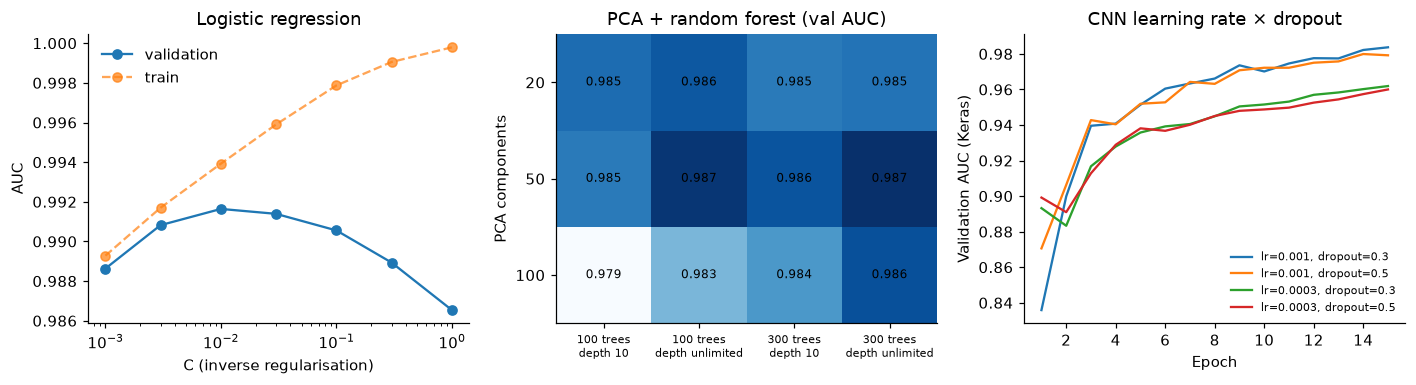

Notebook runtime: 703 s


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].plot(lr_res.C, lr_res.val_auc, "o-", label="validation")
axes[0].plot(lr_res.C, lr_res.train_auc, "o--", label="train", alpha=0.7)
axes[0].set(xscale="log", xlabel="C (inverse regularisation)", ylabel="AUC", title="Logistic regression")
axes[0].legend(frameon=False)

piv = rf_res.pivot_table(index="components", columns=["trees", "max_depth"], values="val_auc")
im = axes[1].imshow(piv.values, cmap="Blues", aspect="auto")
axes[1].set_xticks(range(piv.shape[1]), [f"{t} trees\ndepth {dd}" for t, dd in piv.columns], fontsize=7)
axes[1].set_yticks(range(piv.shape[0]), piv.index)
axes[1].set(ylabel="PCA components", title="PCA + random forest (val AUC)")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        axes[1].text(j, i, f"{piv.values[i, j]:.3f}", ha="center", va="center", fontsize=8)

for key, c in curves.items():
    axes[2].plot(range(1, len(c) + 1), c, label=key)
axes[2].set(xlabel="Epoch", ylabel="Validation AUC (Keras)", title="CNN learning rate × dropout")
axes[2].legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig13_tuning.png")
plt.show()
print(f"Notebook runtime: {time.perf_counter() - nb_start:.0f} s")

## Findings
- **Our original settings were already the best in every grid**, so the final models and the test results in
  04 stand unchanged.
- **Logistic regression:** validation AUC peaks at C = 0.01 (0.9916). Weaker regularisation keeps raising
  train AUC (to 0.9998 at C = 1) while validation falls to 0.9865, which is classic overfitting.
- **PCA + random forest:** 50 components, 300 trees and unlimited depth are best (0.9871). The whole
  12-config grid spans only 0.979–0.987. 100 components is worst, because extra components add noise for the
  forest, and depth limits barely matter.
- **CNN:** learning rate matters far more than dropout. At 15 epochs, 1e-3 reaches 0.984 while 3e-4 reaches
  only about 0.96 and is still climbing. Dropout 0.3 is marginally better than 0.5. All runs were still
  improving at epoch 15, which supports the 30 epochs used for the final model (val AUC 0.992 in 03).
- **Cost:** the full search took about 12 minutes on a laptop CPU. Every CNN run stayed under the 5-minute
  budget (slowest 250 s).